<a href="https://colab.research.google.com/github/chadowsv/model-loa/blob/main/Procesamiento_DatasetModelo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import re
from pathlib import Path
from IPython.display import display
from google.colab import drive, files

# 1 - Carga de Archivos

In [2]:
drive.mount("/content/drive")
CARPETA_DRIVE = Path("/content/drive/MyDrive/ModelLOA/Datos_Iniciales")

ARCHIVO_HOMICIDIOS_2014_2025 = (CARPETA_DRIVE / "mdi_homicidiosintencionales_pm_2014_2025.xlsx")
ARCHIVO_HOMICIDIOS_2026 = (CARPETA_DRIVE / "mdi_homicidiosintencionales_pm_2026_enero_agosto.xlsx")

ARCHIVO_FERIADOS = CARPETA_DRIVE / "feriados_ecuador_2014_2026.csv"
ARCHIVO_SALIDA = CARPETA_DRIVE / "dataset_homicidios_final.csv"

HOJA_2014_2025 = "1. Homicidios Intencionales"
HOJA_2026 = "1. Homicidios Intencionales"

for ruta in [
    ARCHIVO_HOMICIDIOS_2014_2025,
    ARCHIVO_HOMICIDIOS_2026,
    ARCHIVO_FERIADOS
]:
    if not ruta.exists():
        raise FileNotFoundError(
            f"No se encontró: {ruta}\n"
            "Revisa la ruta y el nombre del archivo."
        )


df_2014_2025 = pd.read_excel(
    ARCHIVO_HOMICIDIOS_2014_2025,
    sheet_name=HOJA_2014_2025,
    dtype={"codigo_subcircuito": "string"}
)

df_2026 = pd.read_excel(
    ARCHIVO_HOMICIDIOS_2026,
    sheet_name=HOJA_2026,
    dtype={"codigo_subcircuito": "string"}
)

df_feriados_original = pd.read_csv(
    ARCHIVO_FERIADOS,
    engine="python",
    sep=None,
    encoding="utf-8-sig",
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1.1 - Combinacion de archivos

In [3]:
print("Dimensiones 2014-2025:", df_2014_2025.shape)
print("Dimensiones 2026:", df_2026.shape)

if set(df_2014_2025.columns) != set(df_2026.columns):
    raise ValueError("Los datos tienen columnas diferentes.")

df_2026 = df_2026[df_2014_2025.columns]

df_original = pd.concat(
    [df_2014_2025, df_2026],
    ignore_index=True
)

print("\nDataset combinado:", df_original.shape)

Dimensiones 2014-2025: (39821, 33)
Dimensiones 2026: (5676, 33)

Dataset combinado: (45497, 33)


In [4]:
print("\nPrimeras filas del dataset combinado:")
display(df_original.head())

print("\nPrimeras filas de feriados:")
display(df_feriados_original.head())


Primeras filas del dataset combinado:


,tipo_muerte,zona,subzona,distrito,circuito,codigo_subcircuito,subcircuito,codigo_provincia,provincia,codigo_canton,...,edad,medida_edad,sexo,genero,etnia,estado_civil,nacionalidad,discapacidad,profesion_registro_civil,instruccion
0,FEMICIDIO,ZONA 9,D.M. QUITO,QUITUMBE,TURUBAMBA,17D07C05S06,TURUBAMBA 6,17,PICHINCHA,1701,...,30,A,MUJER,FEMENINO,MESTIZO/A,SIN_DATO,SIN_DATO,NINGUNA,SIN_DATO,SIN_DATO
1,ASESINATO,ZONA 8,D.M. GUAYAQUIL,NUEVA PROSPERINA,NUEVO GUAYAQUIL,09D08C06S01,NUEVO GUAYAQUIL 1,9,GUAYAS,901,...,25,A,HOMBRE,MASCULINO,MESTIZO/A,SIN_DATO,SIN_DATO,NINGUNA,SIN_DATO,SIN_DATO
2,ASESINATO,ZONA 8,D.M. GUAYAQUIL,NUEVA PROSPERINA,NUEVO GUAYAQUIL,09D08C06S01,NUEVO GUAYAQUIL 1,9,GUAYAS,901,...,26,A,HOMBRE,MASCULINO,MESTIZO/A,SIN_DATO,SIN_DATO,NINGUNA,SIN_DATO,SIN_DATO
3,ASESINATO,ZONA 5,GUAYAS,EMPALME,EMPALME CENTRO,09D15C06S01,EMPALME CENTRO 1,9,GUAYAS,908,...,21,A,HOMBRE,MASCULINO,MESTIZO/A,SOLTERO,ECUADOR,NINGUNA,TRABAJADOR GENERAL,SIN_DATO
4,ASESINATO,ZONA 8,D.M. GUAYAQUIL,PORTETE,SUBURBIO,09D04C06S03,SUBURBIO 3,9,GUAYAS,901,...,31,A,HOMBRE,MASCULINO,MESTIZO/A,DIVORCIADO,ECUADOR,NINGUNA,ESTADO PERSONAL,BACHILLERATO



Primeras filas de feriados:


,fecha,nombre_feriado
0,2014/01/01,Año Nuevo
1,2014/03/03,Carnaval
2,2014/03/04,Carnaval
3,2014/04/18,Viernes Santo
4,2014/05/02,Día del Trabajo


# 2 - Inspeccion y Validacion Inicial


In [5]:

def inspeccionar_dataframe(df, nombre):
    print(f"\n{'=' * 60}")
    print(nombre)
    print("=" * 60)

    print("\nDimensiones:", df.shape)

    print("\nColumnas:")
    print(df.columns.tolist())

    print("\nTipos de datos:")
    print(df.dtypes)

    print("\nPrimeras filas:")
    display(df.head())

    print("\nValores nulos por columna:")
    print(df.isna().sum().sort_values(ascending=False))

    print("\nDuplicados exactos:", df.duplicated().sum())

COL_FECHA_FERIADO = "fecha"
COL_NOMBRE_FERIADO = "nombre_feriado"

inspeccionar_dataframe(df_original, "HOMICIDIOS")
inspeccionar_dataframe(df_feriados_original, "FERIADOS")


HOMICIDIOS

Dimensiones: (45497, 33)

Columnas:
['tipo_muerte', 'zona', 'subzona', 'distrito', 'circuito', 'codigo_subcircuito', 'subcircuito', 'codigo_provincia', 'provincia', 'codigo_canton', 'canton', 'coordenada_y', 'coordenada_x', 'area_hecho', 'lugar', 'tipo_lugar', 'fecha_infraccion', 'hora_infraccion', 'arma', 'tipo_arma', 'presunta_motivacion', 'presun_motiva_observada', 'probable_causa_motivada', 'edad', 'medida_edad', 'sexo', 'genero', 'etnia', 'estado_civil', 'nacionalidad', 'discapacidad', 'profesion_registro_civil', 'instruccion']

Tipos de datos:
tipo_muerte                         object
zona                                object
subzona                             object
distrito                            object
circuito                            object
codigo_subcircuito          string[python]
subcircuito                         object
codigo_provincia                     int64
provincia                           object
codigo_canton                        int64
c

,tipo_muerte,zona,subzona,distrito,circuito,codigo_subcircuito,subcircuito,codigo_provincia,provincia,codigo_canton,...,edad,medida_edad,sexo,genero,etnia,estado_civil,nacionalidad,discapacidad,profesion_registro_civil,instruccion
0,FEMICIDIO,ZONA 9,D.M. QUITO,QUITUMBE,TURUBAMBA,17D07C05S06,TURUBAMBA 6,17,PICHINCHA,1701,...,30,A,MUJER,FEMENINO,MESTIZO/A,SIN_DATO,SIN_DATO,NINGUNA,SIN_DATO,SIN_DATO
1,ASESINATO,ZONA 8,D.M. GUAYAQUIL,NUEVA PROSPERINA,NUEVO GUAYAQUIL,09D08C06S01,NUEVO GUAYAQUIL 1,9,GUAYAS,901,...,25,A,HOMBRE,MASCULINO,MESTIZO/A,SIN_DATO,SIN_DATO,NINGUNA,SIN_DATO,SIN_DATO
2,ASESINATO,ZONA 8,D.M. GUAYAQUIL,NUEVA PROSPERINA,NUEVO GUAYAQUIL,09D08C06S01,NUEVO GUAYAQUIL 1,9,GUAYAS,901,...,26,A,HOMBRE,MASCULINO,MESTIZO/A,SIN_DATO,SIN_DATO,NINGUNA,SIN_DATO,SIN_DATO
3,ASESINATO,ZONA 5,GUAYAS,EMPALME,EMPALME CENTRO,09D15C06S01,EMPALME CENTRO 1,9,GUAYAS,908,...,21,A,HOMBRE,MASCULINO,MESTIZO/A,SOLTERO,ECUADOR,NINGUNA,TRABAJADOR GENERAL,SIN_DATO
4,ASESINATO,ZONA 8,D.M. GUAYAQUIL,PORTETE,SUBURBIO,09D04C06S03,SUBURBIO 3,9,GUAYAS,901,...,31,A,HOMBRE,MASCULINO,MESTIZO/A,DIVORCIADO,ECUADOR,NINGUNA,ESTADO PERSONAL,BACHILLERATO



Valores nulos por columna:
tipo_muerte                 0
zona                        0
subzona                     0
distrito                    0
circuito                    0
codigo_subcircuito          0
subcircuito                 0
codigo_provincia            0
provincia                   0
codigo_canton               0
canton                      0
coordenada_y                0
coordenada_x                0
area_hecho                  0
lugar                       0
tipo_lugar                  0
fecha_infraccion            0
hora_infraccion             0
arma                        0
tipo_arma                   0
presunta_motivacion         0
presun_motiva_observada     0
probable_causa_motivada     0
edad                        0
medida_edad                 0
sexo                        0
genero                      0
etnia                       0
estado_civil                0
nacionalidad                0
discapacidad                0
profesion_registro_civil    0
instruccion 

,fecha,nombre_feriado
0,2014/01/01,Año Nuevo
1,2014/03/03,Carnaval
2,2014/03/04,Carnaval
3,2014/04/18,Viernes Santo
4,2014/05/02,Día del Trabajo



Valores nulos por columna:
fecha             0
nombre_feriado    0
dtype: int64

Duplicados exactos: 0


In [6]:
df = df_original.copy()
df_feriados = df_feriados_original.copy()

# 3 - Limpieza

In [7]:
df["codigo_subcircuito_original"] = df["codigo_subcircuito"]

df["codigo_subcircuito"] = (
    df["codigo_subcircuito"]
    .astype("string")
    .str.strip()
    .str.upper()
)

patron_codigo = r"^(\d{2})D(\d{2})C(\d{2})S(\d{2})$"

codigo_valido = df["codigo_subcircuito"].str.fullmatch(
    patron_codigo, na=False
)

df["codigo_provincia"] = (
    df["codigo_subcircuito"]
    .str.extract(patron_codigo, expand=True)[0]
)

distrito_extraido = (
    df["codigo_subcircuito"]
    .str.extract(patron_codigo, expand=True)[1]
)

df["codigo_distrito"] = (
    df["codigo_provincia"] + "D" + distrito_extraido
)

df["fecha"] = pd.to_datetime(
    df["fecha_infraccion"],
    errors="coerce",
    dayfirst=True
).dt.normalize()


def convertir_hora(valor):
    if pd.isna(valor):
        return pd.NaT

    if hasattr(valor, "strftime"):
        try:
            return pd.to_timedelta(valor.strftime("%H:%M:%S"))
        except (ValueError, TypeError):
            return pd.NaT

    texto = str(valor).strip()

    if not texto:
        return pd.NaT

    coincidencia = re.fullmatch(
        r"(\d{1,2}):(\d{2})(?::(\d{2})(?:\.\d+)?)?",
        texto
    )

    if coincidencia:
        h = int(coincidencia.group(1))
        m = int(coincidencia.group(2))
        s = int(coincidencia.group(3) or 0)

        if h <= 23 and m <= 59 and s <= 59:
            return pd.Timedelta(
                hours=h, minutes=m, seconds=s
            )

        return pd.NaT

    try:
        ts = pd.to_datetime(texto, errors="coerce")
        if pd.isna(ts):
            return pd.NaT
        return pd.Timedelta(
            hours=ts.hour,
            minutes=ts.minute,
            seconds=ts.second
        )
    except (ValueError, TypeError, OverflowError):
        return pd.NaT


df["hora_convertida"] = df["hora_infraccion"].apply(
    convertir_hora
)

df["hora_numero"] = (
    df["hora_convertida"].dt.total_seconds() // 3600
).astype("Int64")


df["codigo_invalido"] = ~codigo_valido
df["fecha_invalida"] = df["fecha"].isna()
df["hora_invalida"] = df["hora_convertida"].isna()

print("Registros originales:", len(df))
print("Códigos geográficos inválidos:", df["codigo_invalido"].sum())
print("Fechas inválidas:", df["fecha_invalida"].sum())
print("Horas inválidas:", df["hora_invalida"].sum())

problemas = df[
    df["codigo_invalido"]
    | df["fecha_invalida"]
    | df["hora_invalida"]
].copy()

print("\nRegistros que requieren revisión:", len(problemas))

display(
    problemas[
        [
            "codigo_subcircuito_original",
            "fecha_infraccion",
            "hora_infraccion",
            "codigo_invalido",
            "fecha_invalida",
            "hora_invalida"
        ]
    ].head(30)
)

problemas.to_csv(
    CARPETA_DRIVE / "auditoria_registros_invalidos.csv",
    index=False,
    encoding="utf-8-sig"
)

mascara_valida = (
    codigo_valido
    & df["fecha"].notna()
    & df["hora_convertida"].notna()
)

df_valido = df.loc[mascara_valida].copy()

print("\nRegistros válidos para agregación:", len(df_valido))
print("Registros excluidos del procesamiento:", len(df) - len(df_valido))


Registros originales: 45497
Códigos geográficos inválidos: 0
Fechas inválidas: 0
Horas inválidas: 5

Registros que requieren revisión: 5


,codigo_subcircuito_original,fecha_infraccion,hora_infraccion,codigo_invalido,fecha_invalida,hora_invalida
33804,16D01C01S03,2019-08-25,SIN_DATO,False,False,True
37492,12D02C01S01,2015-12-19,SIN_DATO,False,False,True
39197,23D02C08S01,2014-06-03,SIN_DATO,False,False,True
39736,09D12C05S01,2014-01-18,SIN_DATO,False,False,True
39757,05D02C03S02,2014-01-14,SIN_DATO,False,False,True



Registros válidos para agregación: 45492
Registros excluidos del procesamiento: 5


# 4 - Conversion Franja Horaria

In [8]:
condiciones = [
    df_valido["hora_numero"].between(0, 5),
    df_valido["hora_numero"].between(6, 11),
    df_valido["hora_numero"].between(12, 17),
    df_valido["hora_numero"].between(18, 23)
]

franjas = [
    "madrugada",
    "manana",
    "tarde",
    "noche"
]

df_valido["franja_horaria"] = np.select(
    condiciones,
    franjas,
    default=None
)

if df_valido["franja_horaria"].isna().any():
    raise ValueError(
        "Existen registros válidos sin franja horaria asignada."
    )

columnas_grupo = [
    "codigo_provincia",
    "codigo_distrito",
    "fecha",
    "franja_horaria"
]

df_agregado = (
    df_valido
    .groupby(columnas_grupo, as_index=False)
    .size()
    .rename(columns={"size": "total_homicidios"})
)

df_agregado["total_homicidios"] = (
    df_agregado["total_homicidios"].astype("int64")
)

print("Filas después de la agregación:", len(df_agregado))
print("Total de homicidios contabilizados:", df_agregado["total_homicidios"].sum())

df_agregado.head()


Filas después de la agregación: 36000
Total de homicidios contabilizados: 45492


,codigo_provincia,codigo_distrito,fecha,franja_horaria,total_homicidios
0,01,01D01,2014-01-01,madrugada,1
1,01,01D01,2014-03-22,madrugada,1
2,01,01D01,2014-04-09,tarde,1
3,01,01D01,2014-04-17,noche,1
4,01,01D01,2014-05-29,madrugada,1


# 5 - Completar Fechas

In [9]:
fecha_minima = df_valido["fecha"].min()
fecha_maxima = df_valido["fecha"].max()

print("Fecha mínima:", fecha_minima.date())
print("Fecha máxima:", fecha_maxima.date())

fechas = pd.date_range(
    start=fecha_minima,
    end=fecha_maxima,
    freq="D"
)

franjas = ["madrugada", "manana", "tarde", "noche"]

distritos = (
    df_valido[
        ["codigo_provincia", "codigo_distrito"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

calendario = pd.MultiIndex.from_product(
    [fechas, franjas],
    names=["fecha", "franja_horaria"]
).to_frame(index=False)

df_completo = distritos.merge(calendario, how="cross")

filas_antes = len(df_agregado)

df_completo = df_completo.merge(
    df_agregado,
    on=[
        "codigo_provincia",
        "codigo_distrito",
        "fecha",
        "franja_horaria"
    ],
    how="left",
    validate="one_to_one"
)

df_completo["total_homicidios"] = (
    df_completo["total_homicidios"]
    .fillna(0)
    .astype("int64")
)

print("Filas antes de completar:", filas_antes)
print("Filas después de completar:", len(df_completo))
print("Filas esperadas:", len(distritos) * len(fechas) * 4)

conteo_franjas = df_completo.groupby(
    ["codigo_provincia", "codigo_distrito", "fecha"]
)["franja_horaria"].nunique()

Fecha mínima: 2014-01-01
Fecha máxima: 2026-08-31
Filas antes de completar: 36000
Filas después de completar: 2590560
Filas esperadas: 2590560


# 6 - Incorporacion Feriados

In [10]:
fer = df_feriados[["fecha", "nombre_feriado"]].copy()

fer["fecha"] = pd.to_datetime(
    fer["fecha"], format="%Y/%m/%d", errors="coerce"
)

fer["nombre_feriado"] = fer["nombre_feriado"].str.strip()

df_completo = df_completo.drop(
    columns=[
        c for c in df_completo.columns
        if c.startswith("nombre_feriado") or c == "es_feriado"
    ],
    errors="ignore"
)

df_completo = df_completo.merge(
    fer,
    on="fecha",
    how="left"
)

df_completo["es_feriado"] = (
    df_completo["nombre_feriado"].notna().astype("int8")
)

df_completo["nombre_feriado"] = (
    df_completo["nombre_feriado"].fillna("NO_FERIADO")
)

print("Filas del dataset:", len(df_completo))
print("Total de registros marcados como feriado:", df_completo["es_feriado"].sum())
df_completo.head()

Filas del dataset: 2590560
Total de registros marcados como feriado: 94640


,codigo_provincia,codigo_distrito,fecha,franja_horaria,total_homicidios,nombre_feriado,es_feriado
0,17,17D07,2014-01-01,madrugada,0,Año Nuevo,1
1,17,17D07,2014-01-01,manana,1,Año Nuevo,1
2,17,17D07,2014-01-01,tarde,0,Año Nuevo,1
3,17,17D07,2014-01-01,noche,0,Año Nuevo,1
4,17,17D07,2014-01-02,madrugada,0,NO_FERIADO,0


# 7 - Ingenieria de Variables

In [11]:
# Ordenar los datos
df_completo = df_completo.sort_values(
    ["codigo_provincia", "codigo_distrito", "fecha", "franja_horaria"]
).reset_index(drop=True)

# Año
df_completo["anio"] = df_completo["fecha"].dt.year

# Mes
df_completo["mes"] = df_completo["fecha"].dt.month

# Número del día de la semana
df_completo["dia_semana_num"] = df_completo["fecha"].dt.dayofweek

# Nombre del día de la semana
dias = {
    0: "Lunes",
    1: "Martes",
    2: "Miercoles",
    3: "Jueves",
    4: "Viernes",
    5: "Sabado",
    6: "Domingo"
}

df_completo["dia_semana"] = (
    df_completo["dia_semana_num"].map(dias)
)

df_completo.head()

,codigo_provincia,codigo_distrito,fecha,franja_horaria,total_homicidios,nombre_feriado,es_feriado,anio,mes,dia_semana_num,dia_semana
0,01,01D01,2014-01-01,madrugada,1,Año Nuevo,1,2014,1,2,Miercoles
1,01,01D01,2014-01-01,manana,0,Año Nuevo,1,2014,1,2,Miercoles
2,01,01D01,2014-01-01,noche,0,Año Nuevo,1,2014,1,2,Miercoles
3,01,01D01,2014-01-01,tarde,0,Año Nuevo,1,2014,1,2,Miercoles
4,01,01D01,2014-01-02,madrugada,0,NO_FERIADO,0,2014,1,3,Jueves


In [12]:
df_completo.head(30)

,codigo_provincia,codigo_distrito,fecha,franja_horaria,total_homicidios,nombre_feriado,es_feriado,anio,mes,dia_semana_num,dia_semana
0,01,01D01,2014-01-01,madrugada,1,Año Nuevo,1,2014,1,2,Miercoles
1,01,01D01,2014-01-01,manana,0,Año Nuevo,1,2014,1,2,Miercoles
2,01,01D01,2014-01-01,noche,0,Año Nuevo,1,2014,1,2,Miercoles
3,01,01D01,2014-01-01,tarde,0,Año Nuevo,1,2014,1,2,Miercoles
4,01,01D01,2014-01-02,madrugada,0,NO_FERIADO,0,2014,1,3,Jueves
5,01,01D01,2014-01-02,manana,0,NO_FERIADO,0,2014,1,3,Jueves
6,01,01D01,2014-01-02,noche,0,NO_FERIADO,0,2014,1,3,Jueves
7,01,01D01,2014-01-02,tarde,0,NO_FERIADO,0,2014,1,3,Jueves
8,01,01D01,2014-01-03,madrugada,0,NO_FERIADO,0,2014,1,4,Viernes
9,01,01D01,2014-01-03,manana,0,NO_FERIADO,0,2014,1,4,Viernes


# 8 - Análisis exploratorio

## 8.1 Relación entre el día de la semana y la cantidad de homicidios

In [21]:
# Total de homicidios por fecha
homicidios_diarios = (
    df_completo
    .groupby(
        ["fecha", "anio", "mes", "dia_semana_num", "dia_semana"],
        as_index=False
    )["total_homicidios"]
    .sum()
)

,fecha,anio,mes,dia_semana_num,dia_semana,total_homicidios
0,2014-01-01,2014,1,2,Miercoles,17
1,2014-01-02,2014,1,3,Jueves,4
2,2014-01-03,2014,1,4,Viernes,2
3,2014-01-04,2014,1,5,Sabado,6
4,2014-01-05,2014,1,6,Domingo,4
5,2014-01-06,2014,1,0,Lunes,2
6,2014-01-07,2014,1,1,Martes,2
7,2014-01-08,2014,1,2,Miercoles,3
8,2014-01-09,2014,1,3,Jueves,3
9,2014-01-10,2014,1,4,Viernes,4


In [22]:
# Estadísticas de homicidios según el día de la semana
analisis_dia_semana = (
    homicidios_diarios
    .groupby(
        ["dia_semana_num", "dia_semana"],
        as_index=False
    )
    .agg(
        promedio_homicidios=("total_homicidios", "mean"),
        mediana_homicidios=("total_homicidios", "median"),
        maximo_homicidios=("total_homicidios", "max"),
        cantidad_dias=("fecha", "count")
    )
    .sort_values("dia_semana_num")
)

display(analisis_dia_semana)

,dia_semana_num,dia_semana,total_homicidios
0,0,Lunes,9.190620
1,1,Martes,8.471212
2,2,Miercoles,8.393343
3,3,Jueves,8.773071
4,4,Viernes,9.642965
5,5,Sabado,11.440242
6,6,Domingo,12.924357


In [24]:
analisis_dia_semana = (
    homicidios_diarios
    .groupby(
        ["dia_semana_num", "dia_semana"],
        as_index=False
    )
    .agg(
        promedio_homicidios=("total_homicidios", "mean"),
        mediana_homicidios=("total_homicidios", "median"),
        maximo_homicidios=("total_homicidios", "max"),
        cantidad_dias=("fecha", "count")
    )
    .sort_values("dia_semana_num")
)

display(analisis_dia_semana)

,dia_semana_num,dia_semana,promedio_homicidios,mediana_homicidios,maximo_homicidios,cantidad_dias
0,0,Lunes,9.190620,4.0,64,661
1,1,Martes,8.471212,4.0,129,660
2,2,Miercoles,8.393343,4.0,40,661
3,3,Jueves,8.773071,4.0,44,661
4,4,Viernes,9.642965,5.0,71,661
5,5,Sabado,11.440242,6.0,50,661
6,6,Domingo,12.924357,7.0,82,661


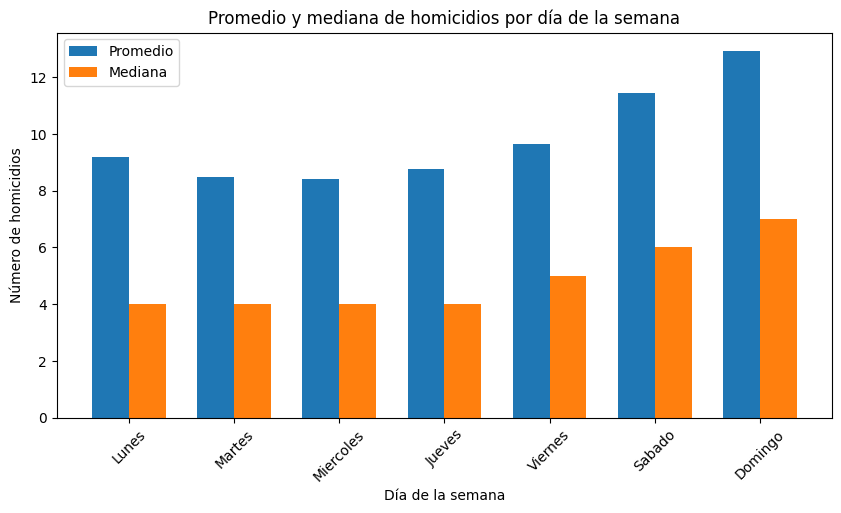

In [25]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(analisis_dia_semana))
ancho = 0.35

plt.figure(figsize=(10, 5))

plt.bar(
    x - ancho/2,
    analisis_dia_semana["promedio_homicidios"],
    ancho,
    label="Promedio"
)

plt.bar(
    x + ancho/2,
    analisis_dia_semana["mediana_homicidios"],
    ancho,
    label="Mediana"
)

plt.xticks(
    x,
    analisis_dia_semana["dia_semana"],
    rotation=45
)

plt.title("Promedio y mediana de homicidios por día de la semana")
plt.xlabel("Día de la semana")
plt.ylabel("Número de homicidios")

plt.legend()

plt.show()
plt.show()

## 8.2 Relación entre la franja horaria y la cantidad de homicidios

In [26]:
# Total de homicidios por fecha y franja horaria
homicidios_por_franja = (
    df_completo
    .groupby(
        ["fecha", "franja_horaria"],
        as_index=False
    )["total_homicidios"]
    .sum()
)

display(homicidios_por_franja.head(12))

,fecha,franja_horaria,total_homicidios
0,2014-01-01,madrugada,3
1,2014-01-01,manana,8
2,2014-01-01,noche,3
3,2014-01-01,tarde,3
4,2014-01-02,madrugada,2
5,2014-01-02,manana,0
6,2014-01-02,noche,0
7,2014-01-02,tarde,2
8,2014-01-03,madrugada,0
9,2014-01-03,manana,1


In [27]:
# Estadísticas de homicidios según la franja horaria
analisis_franja = (
    homicidios_por_franja
    .groupby(
        "franja_horaria",
        as_index=False
    )
    .agg(
        promedio_homicidios=("total_homicidios", "mean"),
        mediana_homicidios=("total_homicidios", "median"),
        maximo_homicidios=("total_homicidios", "max"),
        cantidad_dias=("fecha", "count")
    )
)

display(analisis_franja)

,franja_horaria,promedio_homicidios,mediana_homicidios,maximo_homicidios,cantidad_dias
0,madrugada,1.929745,1.0,49,4626
1,manana,1.523346,1.0,81,4626
2,noche,3.865543,2.0,91,4626
3,tarde,2.515348,1.0,32,4626


In [28]:
orden_franjas = [
    "madrugada",
    "manana",
    "tarde",
    "noche"
]

analisis_franja["franja_horaria"] = pd.Categorical(
    analisis_franja["franja_horaria"],
    categories=orden_franjas,
    ordered=True
)

analisis_franja = analisis_franja.sort_values(
    "franja_horaria"
)

display(analisis_franja)

,franja_horaria,promedio_homicidios,mediana_homicidios,maximo_homicidios,cantidad_dias
0,madrugada,1.929745,1.0,49,4626
1,manana,1.523346,1.0,81,4626
3,tarde,2.515348,1.0,32,4626
2,noche,3.865543,2.0,91,4626


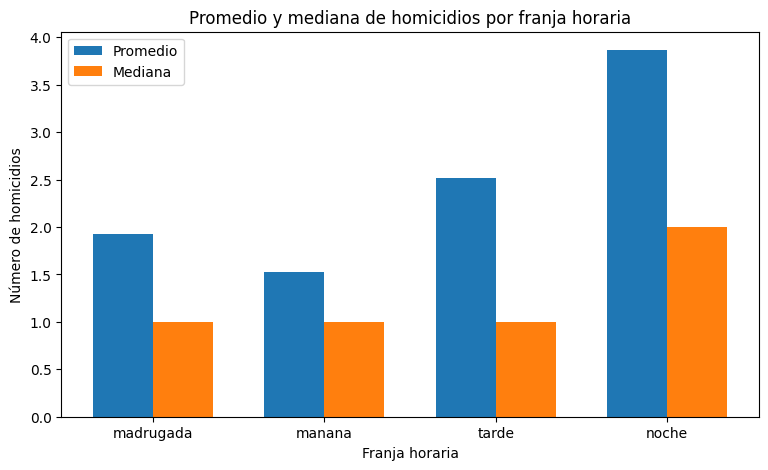

In [29]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(analisis_franja))
ancho = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - ancho/2,
    analisis_franja["promedio_homicidios"],
    ancho,
    label="Promedio"
)

plt.bar(
    x + ancho/2,
    analisis_franja["mediana_homicidios"],
    ancho,
    label="Mediana"
)

plt.xticks(
    x,
    analisis_franja["franja_horaria"]
)

plt.title(
    "Promedio y mediana de homicidios por franja horaria"
)

plt.xlabel("Franja horaria")
plt.ylabel("Número de homicidios")

plt.legend()
plt.show()

## 8.3 Relación entre el mes y la cantidad de homicidios

In [30]:
analisis_mes = (
    homicidios_diarios
    .groupby(
        "mes",
        as_index=False
    )
    .agg(
        promedio_homicidios=("total_homicidios", "mean"),
        mediana_homicidios=("total_homicidios", "median"),
        maximo_homicidios=("total_homicidios", "max"),
        cantidad_dias=("fecha", "count")
    )
)

display(analisis_mes)

,mes,promedio_homicidios,mediana_homicidios,maximo_homicidios,cantidad_dias
0,1,9.307692,5.0,64,403
1,2,9.558583,5.0,85,367
2,3,9.669975,5.0,50,403
3,4,9.782051,5.5,43,390
4,5,10.369727,5.0,54,403
5,6,9.725641,5.0,43,390
6,7,9.756824,5.0,55,403
7,8,9.866005,5.0,59,403
8,9,9.955556,5.0,129,360
9,10,9.798387,4.0,44,372


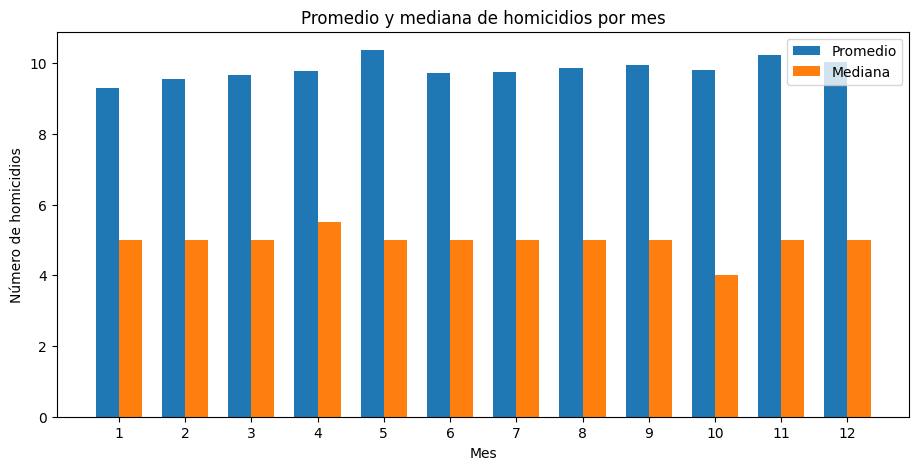

In [31]:
x = np.arange(len(analisis_mes))
ancho = 0.35

plt.figure(figsize=(11, 5))

plt.bar(
    x - ancho/2,
    analisis_mes["promedio_homicidios"],
    ancho,
    label="Promedio"
)

plt.bar(
    x + ancho/2,
    analisis_mes["mediana_homicidios"],
    ancho,
    label="Mediana"
)

plt.xticks(
    x,
    analisis_mes["mes"]
)

plt.title(
    "Promedio y mediana de homicidios por mes"
)

plt.xlabel("Mes")
plt.ylabel("Número de homicidios")

plt.legend()
plt.show()

## 8.4 Relación entre feriados y cantidad de homicidios

In [32]:
homicidios_feriados = (
    df_completo
    .groupby(
        ["fecha", "es_feriado"],
        as_index=False
    )["total_homicidios"]
    .sum()
)

display(homicidios_feriados.head(10))

,fecha,es_feriado,total_homicidios
0,2014-01-01,1,17
1,2014-01-02,0,4
2,2014-01-03,0,2
3,2014-01-04,0,6
4,2014-01-05,0,4
5,2014-01-06,0,2
6,2014-01-07,0,2
7,2014-01-08,0,3
8,2014-01-09,0,3
9,2014-01-10,0,4


In [36]:
analisis_feriado = (
    homicidios_feriados
    .groupby(
        "es_feriado",
        as_index=False
    )
    .agg(
        promedio_homicidios=("total_homicidios", "mean"),
        mediana_homicidios=("total_homicidios", "median"),
        maximo_homicidios=("total_homicidios", "max"),
        cantidad_dias=("fecha", "count")
    )
)

display(analisis_feriado)

,es_feriado,promedio_homicidios,mediana_homicidios,maximo_homicidios,cantidad_dias
0,0,9.776531,5.0,129,4457
1,1,11.349112,7.0,64,169


In [37]:
analisis_feriado["tipo_dia"] = (
    analisis_feriado["es_feriado"]
    .map({
        0: "No feriado",
        1: "Feriado"
    })
)

display(analisis_feriado)

,es_feriado,promedio_homicidios,mediana_homicidios,maximo_homicidios,cantidad_dias,tipo_dia
0,0,9.776531,5.0,129,4457,No feriado
1,1,11.349112,7.0,64,169,Feriado


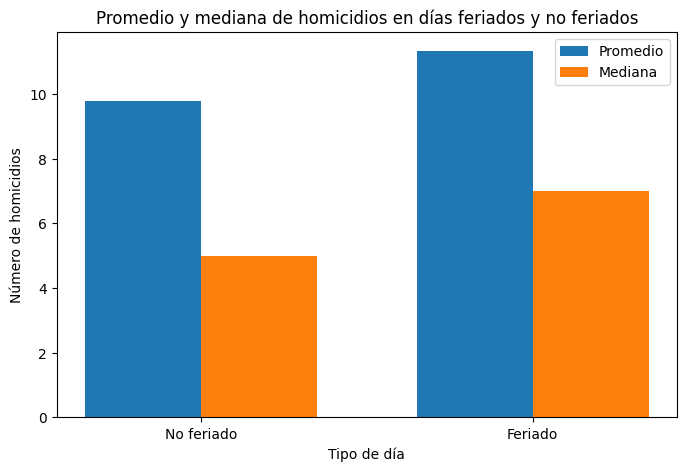

In [38]:
x = np.arange(len(analisis_feriado))
ancho = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - ancho/2,
    analisis_feriado["promedio_homicidios"],
    ancho,
    label="Promedio"
)

plt.bar(
    x + ancho/2,
    analisis_feriado["mediana_homicidios"],
    ancho,
    label="Mediana"
)

plt.xticks(
    x,
    analisis_feriado["tipo_dia"]
)

plt.title(
    "Promedio y mediana de homicidios en días feriados y no feriados"
)

plt.xlabel("Tipo de día")
plt.ylabel("Número de homicidios")

plt.legend()
plt.show()

# 9 - Distribucion Categorica

In [13]:
conteos = df_completo["total_homicidios"]

print("Distribución de total_homicidios:")
display(
    conteos.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).to_frame("valor")
)

frecuencias = (
    conteos.value_counts()
    .sort_index()
    .rename_axis("total_homicidios")
    .to_frame("frecuencia")
)

frecuencias["porcentaje"] = (
    frecuencias["frecuencia"] / len(df_completo) * 100
).round(2)

display(frecuencias)

porcentaje_ceros = conteos.eq(0).mean() * 100
positivos = conteos[conteos > 0]

print(f"Porcentaje de ceros: {porcentaje_ceros:.2f}%")
print(f"Porcentaje de valores positivos: {(conteos > 0).mean() * 100:.2f}%")

if len(positivos) > 0:
    print("\nDistribución de conteos positivos:")
    display(
        positivos.describe(
            percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
        ).to_frame("valor")
    )

    umbral_sugerido = int(np.ceil(positivos.quantile(0.75)))

    # Si el percentil no separa los valores positivos,
    # usar 2 como umbral de alta permite distinguir 1 de 2 o más.
    if umbral_sugerido <= int(positivos.min()):
        umbral_sugerido = 2
else:
    umbral_sugerido = None

print("\nUmbral superior sugerido:", umbral_sugerido)

# DECISIÓN METODOLÓGICA EDITABLE.
# Revisa la distribución y cambia el umbral si es necesario.
UMBRAL_ALTA = umbral_sugerido

if UMBRAL_ALTA is None:
    df_completo["categoria_incidencia"] = "baja"
else:
    df_completo["categoria_incidencia"] = np.select(
        [
            df_completo["total_homicidios"].eq(0),
            df_completo["total_homicidios"].ge(UMBRAL_ALTA)
        ],
        [
            "baja",
            "alta"
        ],
        default="media"
    )

distribucion_categoria = (
    df_completo["categoria_incidencia"]
    .value_counts()
    .reindex(["baja", "media", "alta"], fill_value=0)
    .to_frame("filas")
)

distribucion_categoria["porcentaje"] = (
    distribucion_categoria["filas"] / len(df_completo) * 100
).round(2)

print("\nDistribución de categorías con el umbral propuesto:")
display(distribucion_categoria)

Distribución de total_homicidios:


,valor
count,2.590560e+06
mean,1.756068e-02
std,1.912110e-01
min,0.000000e+00
25%,0.000000e+00
50%,0.000000e+00
75%,0.000000e+00
90%,0.000000e+00
95%,0.000000e+00
99%,1.000000e+00


,frecuencia,porcentaje
total_homicidios,,
0,2554560,98.61
1,29994,1.16
2,4255,0.16
3,1075,0.04
4,372,0.01
5,140,0.01
6,63,0.00
7,37,0.00
8,24,0.00


Porcentaje de ceros: 98.61%
Porcentaje de valores positivos: 1.39%

Distribución de conteos positivos:


,valor
count,36000.000000
mean,1.263667
std,1.027785
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
90%,2.000000
95%,2.000000
max,88.000000



Umbral superior sugerido: 2

Distribución de categorías con el umbral propuesto:


,filas,porcentaje
categoria_incidencia,,
baja,2554560,98.61
media,29994,1.16
alta,6006,0.23


In [14]:
df_completo

,codigo_provincia,codigo_distrito,fecha,franja_horaria,total_homicidios,nombre_feriado,es_feriado,anio,mes,dia_semana_num,dia_semana,categoria_incidencia
0,01,01D01,2014-01-01,madrugada,1,Año Nuevo,1,2014,1,2,Miercoles,media
1,01,01D01,2014-01-01,manana,0,Año Nuevo,1,2014,1,2,Miercoles,baja
2,01,01D01,2014-01-01,noche,0,Año Nuevo,1,2014,1,2,Miercoles,baja
3,01,01D01,2014-01-01,tarde,0,Año Nuevo,1,2014,1,2,Miercoles,baja
4,01,01D01,2014-01-02,madrugada,0,NO_FERIADO,0,2014,1,3,Jueves,baja
...,...,...,...,...,...,...,...,...,...,...,...,...
2590555,24,24D02,2026-08-30,tarde,0,NO_FERIADO,0,2026,8,6,Domingo,baja
2590556,24,24D02,2026-08-31,madrugada,0,NO_FERIADO,0,2026,8,0,Lunes,baja
2590557,24,24D02,2026-08-31,manana,0,NO_FERIADO,0,2026,8,0,Lunes,baja
2590558,24,24D02,2026-08-31,noche,3,NO_FERIADO,0,2026,8,0,Lunes,alta


In [16]:
homicidios_diarios = (
    df_completo
    .groupby(
        ["fecha", "anio", "mes", "dia_semana_num", "dia_semana"]
    )["total_homicidios"]
    .sum()
    .reset_index()
)

homicidios_diarios.head()

,fecha,anio,mes,dia_semana_num,dia_semana,total_homicidios
0,2014-01-01,2014,1,2,Miercoles,17
1,2014-01-02,2014,1,3,Jueves,4
2,2014-01-03,2014,1,4,Viernes,2
3,2014-01-04,2014,1,5,Sabado,6
4,2014-01-05,2014,1,6,Domingo,4


# 10 - Validacion Final

In [18]:
# Ordenar los datos por provincia, distrito, fecha y franja horaria
df_completo = df_completo.sort_values(
    [
        "codigo_provincia",
        "codigo_distrito",
        "fecha",
        "franja_horaria"
    ]
).reset_index(drop=True)

# Año
# 2026-10-28 -> 2026
df_completo["anio"] = df_completo["fecha"].dt.year


# Mes
# 2026-10-28 -> 10
df_completo["mes"] = df_completo["fecha"].dt.month


# Número del día de la semana
#
# Pandas utiliza:
# 0 = lunes
# 1 = martes
# 2 = miércoles
# 3 = jueves
# 4 = viernes
# 5 = sábado
# 6 = domingo
df_completo["dia_semana_num"] = (
    df_completo["fecha"].dt.dayofweek
)


# Diccionario para convertir el número en el nombre del día
dias = {
    0: "Lunes",
    1: "Martes",
    2: "Miercoles",
    3: "Jueves",
    4: "Viernes",
    5: "Sabado",
    6: "Domingo"
}


# Crear nombre del día
df_completo["dia_semana"] = (
    df_completo["dia_semana_num"].map(dias)
)


# Revisar resultado
print("Variables de fecha creadas correctamente:")

display(
    df_completo[
        [
            "fecha",
            "anio",
            "mes",
            "dia_semana_num",
            "dia_semana"
        ]
    ].head(10)
)

Variables de fecha creadas correctamente:


,fecha,anio,mes,dia_semana_num,dia_semana
0,2014-01-01,2014,1,2,Miercoles
1,2014-01-01,2014,1,2,Miercoles
2,2014-01-01,2014,1,2,Miercoles
3,2014-01-01,2014,1,2,Miercoles
4,2014-01-02,2014,1,3,Jueves
5,2014-01-02,2014,1,3,Jueves
6,2014-01-02,2014,1,3,Jueves
7,2014-01-02,2014,1,3,Jueves
8,2014-01-03,2014,1,4,Viernes
9,2014-01-03,2014,1,4,Viernes


# 11 - Exportacion

In [19]:
df_exportar = df_final.copy()

df_exportar["fecha"] = df_exportar["fecha"].dt.strftime("%d/%m/%Y")

df_exportar.to_csv(
    ARCHIVO_SALIDA,
    index=False,
    encoding="utf-8-sig"
)

print("\nArchivo generado:", ARCHIVO_SALIDA)
print("Filas exportadas:", len(df_exportar))
print("Columnas exportadas:", len(df_exportar.columns))



Archivo generado: /content/drive/MyDrive/ModelLOA/Datos_Iniciales/dataset_homicidios_final.csv
Filas exportadas: 2590560
Columnas exportadas: 11
